# Email dataset analysis

This notebook profiles `data/emails.csv` with pandas using a single chunked pass. The source file is too large to load safely into memory, so messages are processed in bounded batches and only compact aggregates are retained. Full message bodies are not displayed.

In [1]:
from collections import Counter
from pathlib import Path
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

ENV_PATH = Path(r"H:\masterswork\gitrash\CLM\CLMClient\.env")
load_dotenv(ENV_PATH)
if hf_api_key := os.getenv("HUGGINGFACE_API_KEY"):
    os.environ.setdefault("HF_TOKEN", hf_api_key)

CSV_PATH = Path(r"H:\masterswork\gitrash\data\emails.csv")
CHUNK_SIZE = 20_000

if not CSV_PATH.is_file():
    raise FileNotFoundError(f"Email dataset not found: {CSV_PATH}")

print(f"Dataset: {CSV_PATH}")
print(f"Size: {CSV_PATH.stat().st_size / (1024 ** 3):.2f} GiB")
print(f"Pandas: {pd.__version__}")

Dataset: H:\masterswork\gitrash\data\emails.csv
Size: 1.33 GiB
Pandas: 2.2.3


## Safe sample

Inspect paths and selected headers only. This avoids printing potentially sensitive message bodies.

In [2]:
sample = pd.read_csv(CSV_PATH, nrows=5, usecols=["file", "message"])
sample_view = pd.DataFrame({
    "file": sample["file"],
    "from": sample["message"].str.extract(r"(?m)^From:\s*([^\r\n]+)", expand=False),
    "to": sample["message"].str.extract(r"(?m)^To:\s*([^\r\n]+)", expand=False),
    "subject": sample["message"].str.extract(r"(?m)^Subject:\s*([^\r\n]*)", expand=False),
})
display(sample_view)

,file,from,to,subject
0,allen-p/_sent_mail/1.,phillip.allen@enron.com,tim.belden@enron.com,Mime-Version: 1.0
1,allen-p/_sent_mail/10.,phillip.allen@enron.com,john.lavorato@enron.com,Re:
2,allen-p/_sent_mail/100.,phillip.allen@enron.com,leah.arsdall@enron.com,Re: test
3,allen-p/_sent_mail/1000.,phillip.allen@enron.com,randall.gay@enron.com,Mime-Version: 1.0
4,allen-p/_sent_mail/1001.,phillip.allen@enron.com,greg.piper@enron.com,Re: Hello


## Complete chunked profile

The following cell scans every row once. Duplicate detection uses stable pandas hashes while retaining only hash integers, and message lengths are retained as compact NumPy arrays for exact percentiles. Header extraction intentionally reads only the first physical line of each header; folded continuation lines are not included.

In [3]:
row_count = 0
missing = Counter()
seen_hashes = set()
duplicate_rows = 0
message_lengths = []
owner_counts = Counter()
folder_counts = Counter()
sender_counts = Counter()
recipient_counts = Counter()
year_counts = Counter()
missing_headers = Counter()

header_patterns = {
    "from": r"(?m)^From:\s*([^\r\n]+)",
    "to": r"(?m)^To:\s*([^\r\n]+)",
    "date": r"(?m)^Date:\s*([^\r\n]+)",
    "message_id": r"(?m)^Message-ID:\s*([^\r\n]+)",
}

reader = pd.read_csv(
    CSV_PATH,
    usecols=["file", "message"],
    chunksize=CHUNK_SIZE,
    dtype={"file": "string", "message": "string"},
)

for chunk_number, chunk in enumerate(reader, start=1):
    row_count += len(chunk)
    missing.update(chunk.isna().sum().to_dict())

    row_hashes = pd.util.hash_pandas_object(chunk[["file", "message"]], index=False).to_numpy(dtype="uint64")
    for row_hash in row_hashes:
        value = int(row_hash)
        if value in seen_hashes:
            duplicate_rows += 1
        else:
            seen_hashes.add(value)

    files = chunk["file"].fillna("")
    messages = chunk["message"].fillna("")
    message_lengths.append(messages.str.len().to_numpy(dtype="int32"))

    path_parts = files.str.split("/")
    owner_counts.update(path_parts.str[0].loc[lambda values: values.ne("")].tolist())
    folder_counts.update(path_parts.str[1].loc[lambda values: values.notna() & values.ne("")].tolist())

    headers = {
        name: messages.str.extract(pattern, expand=False).str.strip()
        for name, pattern in header_patterns.items()
    }
    for name, values in headers.items():
        missing_headers[name] += int(values.isna().sum())

    sender_counts.update(headers["from"].dropna().str.lower().tolist())
    for recipient_line in headers["to"].dropna():
        recipient_counts.update(
            address.strip().lower()
            for address in recipient_line.split(",")
            if address.strip()
        )

    parsed_dates = pd.to_datetime(headers["date"], errors="coerce", utc=True, format="mixed")
    year_counts.update(parsed_dates.dt.year.dropna().astype("int16").tolist())

    if chunk_number == 1 or chunk_number % 5 == 0:
        print(f"Processed {row_count:,} rows")

lengths = np.concatenate(message_lengths)
print(f"Completed: {row_count:,} rows")

Processed 20,000 rows
Processed 100,000 rows
Processed 200,000 rows
Processed 300,000 rows
Processed 400,000 rows
Processed 500,000 rows
Completed: 517,401 rows


## Results

In [4]:
length_percentiles = np.percentile(lengths, [0, 25, 50, 75, 90, 95, 99, 100])
summary = pd.Series({
    "rows": row_count,
    "columns": 2,
    "missing_file": missing["file"],
    "missing_message": missing["message"],
    "duplicate_rows": duplicate_rows,
    "unique_row_hashes": len(seen_hashes),
    "mean_message_characters": float(lengths.mean()),
    "median_message_characters": float(np.median(lengths)),
})
display(summary.to_frame("value"))

display(pd.DataFrame({
    "percentile": ["min", "25%", "50%", "75%", "90%", "95%", "99%", "max"],
    "message_characters": length_percentiles.astype("int64"),
}))

display(pd.Series(missing_headers, name="missing_count").rename_axis("header").to_frame())

,value
rows,517401.000000
columns,2.000000
missing_file,0.000000
missing_message,0.000000
duplicate_rows,0.000000
unique_row_hashes,517401.000000
mean_message_characters,2719.685231
median_message_characters,1529.000000


,percentile,message_characters
0,min,383
1,25%,902
2,50%,1529
3,75%,2698
4,90%,5091
5,95%,7817
6,99%,19126
7,max,2011941


,missing_count
header,
from,0
to,20196
date,0
message_id,0


In [5]:
def counter_frame(counter, label, limit=15):
    return pd.DataFrame(counter.most_common(limit), columns=[label, "count"])

top_owners = counter_frame(owner_counts, "mailbox_owner")
top_folders = counter_frame(folder_counts, "folder")
top_senders = counter_frame(sender_counts, "sender")
top_recipients = counter_frame(recipient_counts, "recipient")
emails_by_year = pd.DataFrame(sorted(year_counts.items()), columns=["year", "count"])

display(top_owners)
display(top_folders)
display(top_senders)
display(top_recipients)
display(emails_by_year)

,mailbox_owner,count
0,kaminski-v,28465
1,dasovich-j,28234
2,kean-s,25351
3,mann-k,23381
4,jones-t,19950
5,shackleton-s,18687
6,taylor-m,13875
7,farmer-d,13032
8,germany-c,12436
9,beck-s,11830


,folder,count
0,all_documents,128103
1,discussion_threads,58609
2,sent,57653
3,deleted_items,51356
4,inbox,44859
5,sent_items,37921
6,notes_inbox,36665
7,_sent_mail,30109
8,calendar,6133
9,archiving,4477


,sender,count
0,kay.mann@enron.com,16735
1,vince.kaminski@enron.com,14368
2,jeff.dasovich@enron.com,11411
3,pete.davis@enron.com,9149
4,chris.germany@enron.com,8801
5,sara.shackleton@enron.com,8777
6,enron.announcements@enron.com,8587
7,tana.jones@enron.com,8490
8,steven.kean@enron.com,6759
9,kate.symes@enron.com,5438


,recipient,count
0,pete.davis@enron.com,9191
1,jeff.dasovich@enron.com,7983
2,tana.jones@enron.com,7853
3,steven.kean@enron.com,7376
4,sara.shackleton@enron.com,7269
5,richard.shapiro@enron.com,7189
6,mark.taylor@enron.com,6067
7,louise.kitchen@enron.com,4954
8,vkaminski@aol.com,4950
9,sally.beck@enron.com,4653


,year,count
0,1980,522
1,1986,2
2,1997,437
3,1998,177
4,1999,11144
5,2000,196100
6,2001,272964
7,2002,35974
8,2004,70
9,2005,1


## Visual overview

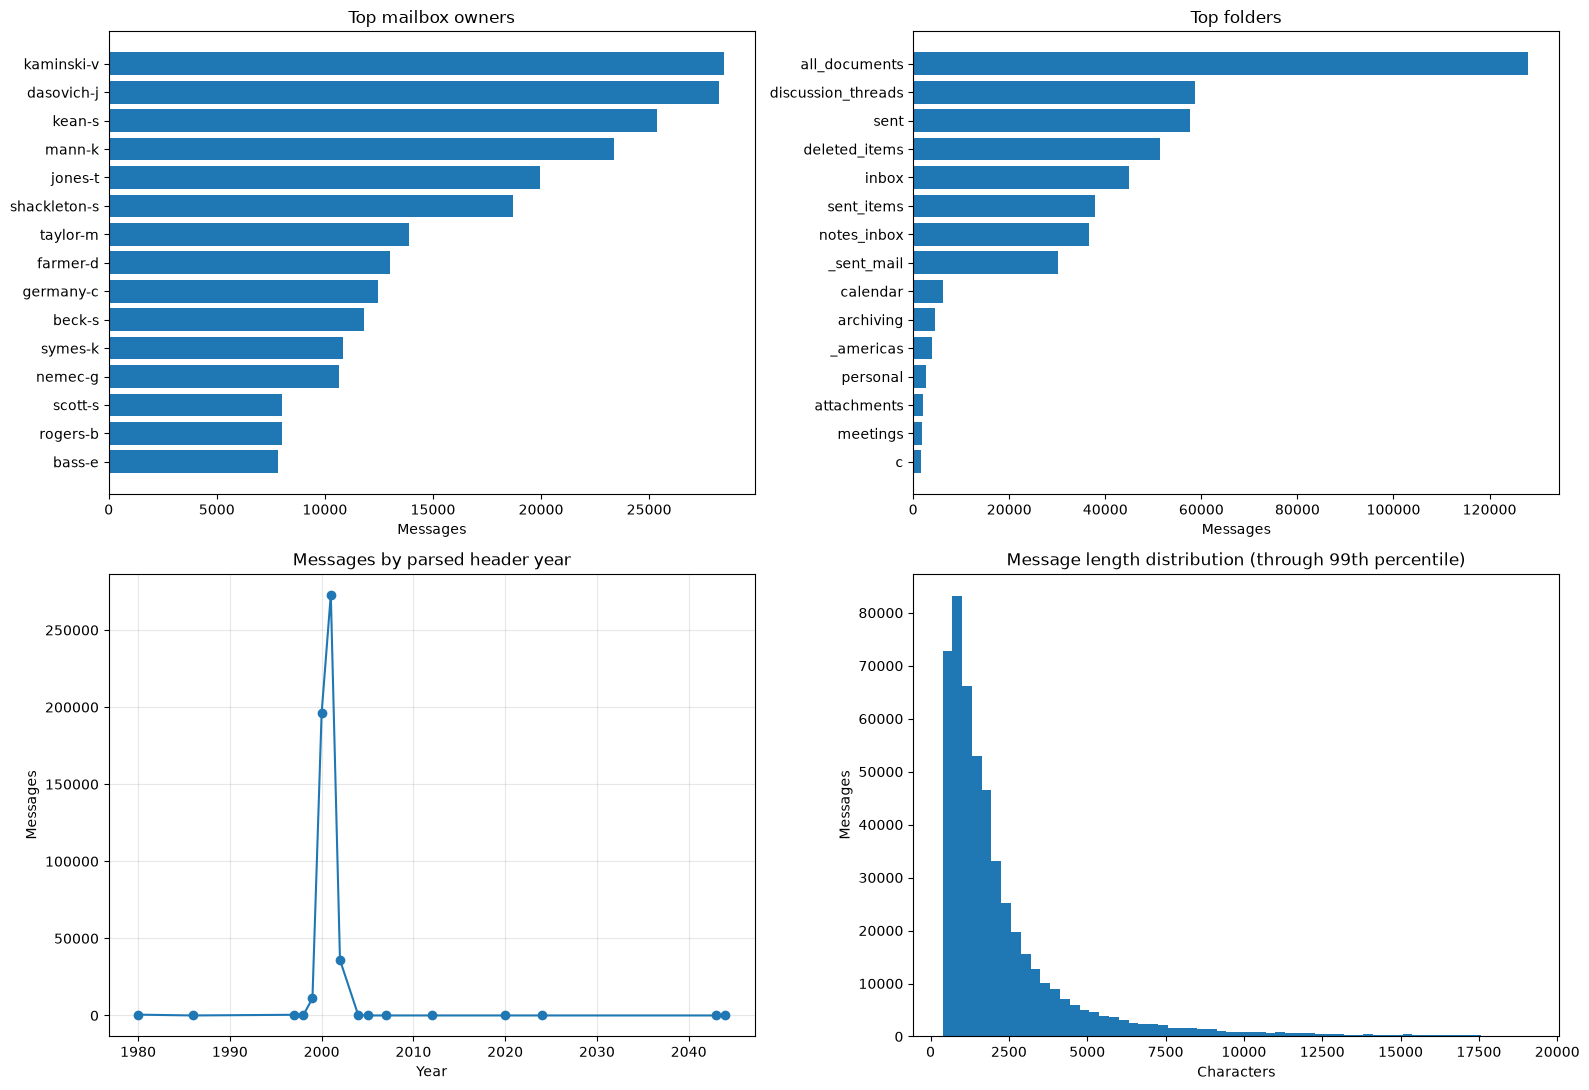

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].barh(top_owners["mailbox_owner"][::-1], top_owners["count"][::-1])
axes[0, 0].set_title("Top mailbox owners")
axes[0, 0].set_xlabel("Messages")

axes[0, 1].barh(top_folders["folder"][::-1], top_folders["count"][::-1])
axes[0, 1].set_title("Top folders")
axes[0, 1].set_xlabel("Messages")

axes[1, 0].plot(emails_by_year["year"], emails_by_year["count"], marker="o")
axes[1, 0].set_title("Messages by parsed header year")
axes[1, 0].set_xlabel("Year")
axes[1, 0].set_ylabel("Messages")
axes[1, 0].grid(alpha=0.3)

plot_lengths = lengths[lengths > 0]
upper = np.percentile(plot_lengths, 99)
axes[1, 1].hist(plot_lengths[plot_lengths <= upper], bins=60)
axes[1, 1].set_title("Message length distribution (through 99th percentile)")
axes[1, 1].set_xlabel("Characters")
axes[1, 1].set_ylabel("Messages")

plt.tight_layout()
plt.show()

## Interpretation guide

- `duplicate_rows` counts repeated `(file, message)` pairs across the complete dataset.
- Missing-header counts distinguish absent metadata from missing CSV fields.
- Sender and recipient values are normalized to lowercase, but malformed source headers are preserved rather than guessed.
- Recipient counts cover addresses on the first physical `To:` header line. Folded continuation lines and `Cc:`/`Bcc:` are intentionally excluded.
- Date parsing uses UTC and reports only successfully parsed years.
- The length histogram is capped at the 99th percentile so unusually large messages do not hide the main distribution.

## Hugging Face classifier dataset

The `jason23322/high-accuracy-email-classifier` dataset is access-gated. Before loading it for the first time:

1. Open https://huggingface.co/datasets/jason23322/high-accuracy-email-classifier and accept the access conditions while signed in.
2. Create a read token at https://huggingface.co/settings/tokens.
3. In a terminal, run `H:\masterswork\gitrash\CLM\CLMClient\.venv\Scripts\hf.exe auth login` and paste the token when prompted.
4. Restart the notebook kernel, then run the cell below.

The token is stored by Hugging Face in the user profile and is never written into this notebook.

In [ ]:
import pandas as pd
from huggingface_hub import get_token

HF_DATASET = "jason23322/high-accuracy-email-classifier"
splits = {"train": "train.json", "test": "test.json"}
hf_token = get_token()

if hf_token is None:
    print("Hugging Face login is required. Follow the steps in the cell above, then rerun this cell.")
else:
    dataframes = {
        split: pd.read_json(
            f"hf://datasets/{HF_DATASET}/{filename}",
            storage_options={"token": hf_token},
        )
        for split, filename in splits.items()
    }
    df = dataframes["train"]
    test_df = dataframes["test"]
    print(f"Train: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(f"Test:  {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
    display(df.head())